# 06 · Regresión: ¿qué explica el impacto de un artículo?
Complemento del pipeline de minería (notebook 01–02) con los modelos de regresión de la asignatura de ML.

**Pregunta:** a partir de las características de un artículo (año, colaboración, tema, acceso abierto…),
¿se puede estimar su impacto, medido como citas por año? Responderla ayuda a entender qué tipo de trabajo
tiene más influencia en el área y, por tanto, qué enfoque conviene para el proyecto.

**Variable objetivo:** `log(1 + citas_por_anio)`. Se usa el logaritmo porque las citas tienen una cola muy larga.
**Modelos:** regresión lineal, polinomial, Ridge, Lasso y Elastic Net (con Grid Search), comparados con un
Random Forest como referencia no lineal.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "figuras" / "06_regresion"; OUT = ROOT / "data" / "processed"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
SEED = 42

df = pd.read_csv(OUT / "articulos_con_clusters.csv")
df = df[df["anio"] <= 2024].copy()  # los trabajos de 2025-2026 aún no han tenido tiempo de acumular citas
df["y"] = np.log1p(df["citas_por_anio"])
print("Artículos para regresión:", len(df))

NUM = ["anio", "n_autores", "n_paises", "n_referencias", "n_keywords", "long_resumen", "n_consultas"]
BIN = ["acceso_abierto", "tiene_resumen", "tema_vision", "tema_sensores", "tema_ml", "tema_clinico"]
CAT = ["perfil", "tipo"]
for c in BIN:
    df[c] = df[c].astype(int)
df["n_paises"] = df["n_paises"].fillna(0)
X, y = df[NUM + BIN + CAT], df["y"]

Artículos para regresión: 3098


**Decisiones:** se excluyen 2025–2026 porque un artículo reciente tiene pocas citas por falta de tiempo, no por bajo
impacto. No se usan variables que contengan la respuesta (citas, FWCI, flags de outlier) para evitar fuga de información.
Partición 80/20 y validación cruzada de 5 particiones en entrenamiento.

In [2]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
prep = ColumnTransformer([("num", StandardScaler(), NUM + BIN),
                          ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CAT)])
cv = KFold(5, shuffle=True, random_state=SEED)

def pipe(model, poly=False):
    pasos = [("prep", prep)]
    if poly:
        pasos.append(("poly", PolynomialFeatures(degree=2, include_bias=False)))
    return Pipeline(pasos + [("reg", model)])

busquedas = {
    "Lineal": (pipe(LinearRegression()), {}),
    "Polinomial (grado 2) + Ridge": (pipe(Ridge(), poly=True), {"reg__alpha": [10, 100, 1000]}),
    "Ridge": (pipe(Ridge()), {"reg__alpha": np.logspace(-2, 3, 12)}),
    "Lasso": (pipe(Lasso(max_iter=20000)), {"reg__alpha": np.logspace(-4, 0, 12)}),
    "Elastic Net": (pipe(ElasticNet(max_iter=20000)), {"reg__alpha": np.logspace(-4, 0, 8), "reg__l1_ratio": [0.2, 0.5, 0.8]}),
    "Random Forest (referencia)": (pipe(RandomForestRegressor(random_state=SEED, n_jobs=-1)),
                                   {"reg__n_estimators": [300], "reg__max_depth": [6, 12, None], "reg__min_samples_leaf": [5, 20]}),
}
filas, mejores = [], {}
for nombre, (p, grid) in busquedas.items():
    gs = GridSearchCV(p, grid or {"reg__fit_intercept": [True]}, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    gs.fit(X_tr, y_tr)
    mejores[nombre] = gs.best_estimator_
    pred = gs.best_estimator_.predict(X_te)
    filas.append({"modelo": nombre, "RMSE_cv": -gs.best_score_, "R2_test": r2_score(y_te, pred),
                  "RMSE_test": np.sqrt(mean_squared_error(y_te, pred)), "MAE_test": mean_absolute_error(y_te, pred),
                  "parametros": {k.replace("reg__", ""): v for k, v in gs.best_params_.items()}})
res = pd.DataFrame(filas).sort_values("RMSE_cv")
pd.set_option("display.max_colwidth", 120)
res.round(3)

,modelo,RMSE_cv,R2_test,RMSE_test,MAE_test,parametros
5,Random Forest (referencia),0.516,0.548,0.561,0.392,"{'max_depth': 12, 'min_samples_leaf': 5, 'n_estimators': 300}"
1,Polinomial (grado 2) + Ridge,0.561,0.505,0.587,0.424,{'alpha': 100}
4,Elastic Net,0.599,0.414,0.639,0.466,"{'alpha': 0.0013894954943731374, 'l1_ratio': 0.2}"
3,Lasso,0.599,0.412,0.640,0.466,{'alpha': 0.0005336699231206312}
2,Ridge,0.599,0.414,0.639,0.466,{'alpha': 1.873817422860383}
0,Lineal,0.600,0.413,0.640,0.466,{'fit_intercept': True}


## Comparación visual

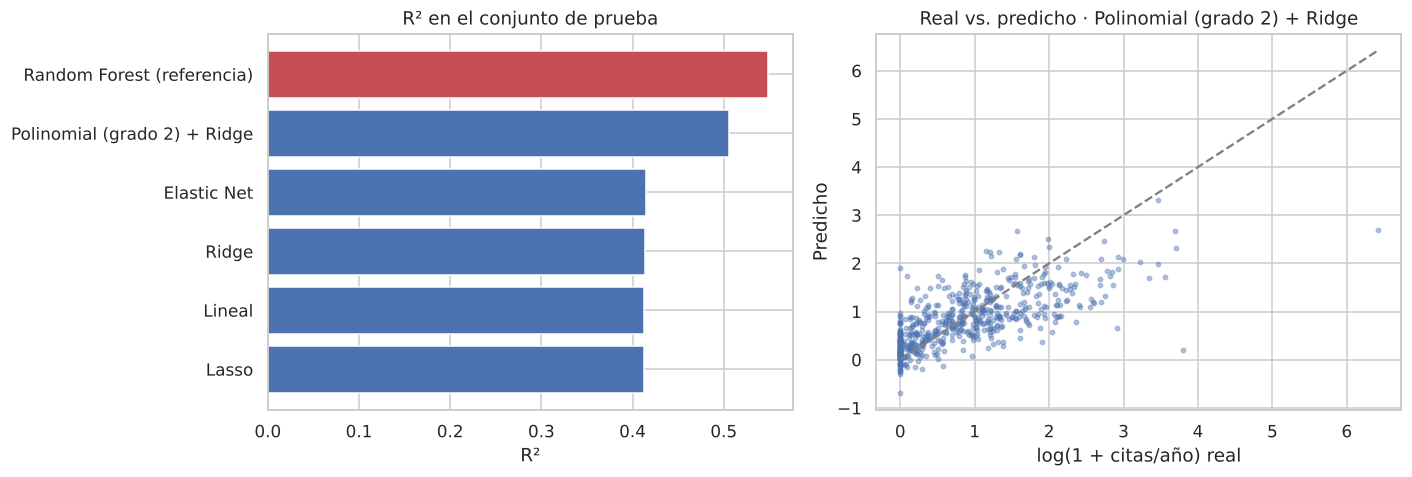

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
r = res.sort_values("R2_test")
axes[0].barh(r["modelo"], r["R2_test"], color=["#C44E52" if "Random" in m else "#4C72B0" for m in r["modelo"]])
axes[0].set(title="R² en el conjunto de prueba", xlabel="R²")
mejor_lineal = res[~res.modelo.str.contains("Random")].iloc[0]["modelo"]
pred = mejores[mejor_lineal].predict(X_te)
pd.DataFrame({"y_real": y_te.values, "y_pred": pred}).to_csv(OUT / "regresion_predicciones_test.csv", index=False)
axes[1].scatter(y_te, pred, s=8, alpha=.4)
lim = [0, max(y_te.max(), pred.max())]
axes[1].plot(lim, lim, "--", c="gray")
axes[1].set(title=f"Real vs. predicho · {mejor_lineal}", xlabel="log(1 + citas/año) real", ylabel="Predicho")
plt.tight_layout(); plt.savefig(FIG / "reg_comparacion.png"); plt.show()

## Lasso como selección de variables
Lasso lleva a cero los coeficientes poco útiles. Los que sobreviven indican qué características se asocian con un
mayor o menor impacto (manteniendo las demás constantes; es asociación, no causalidad).

Variables retenidas por Lasso: 27 de 29


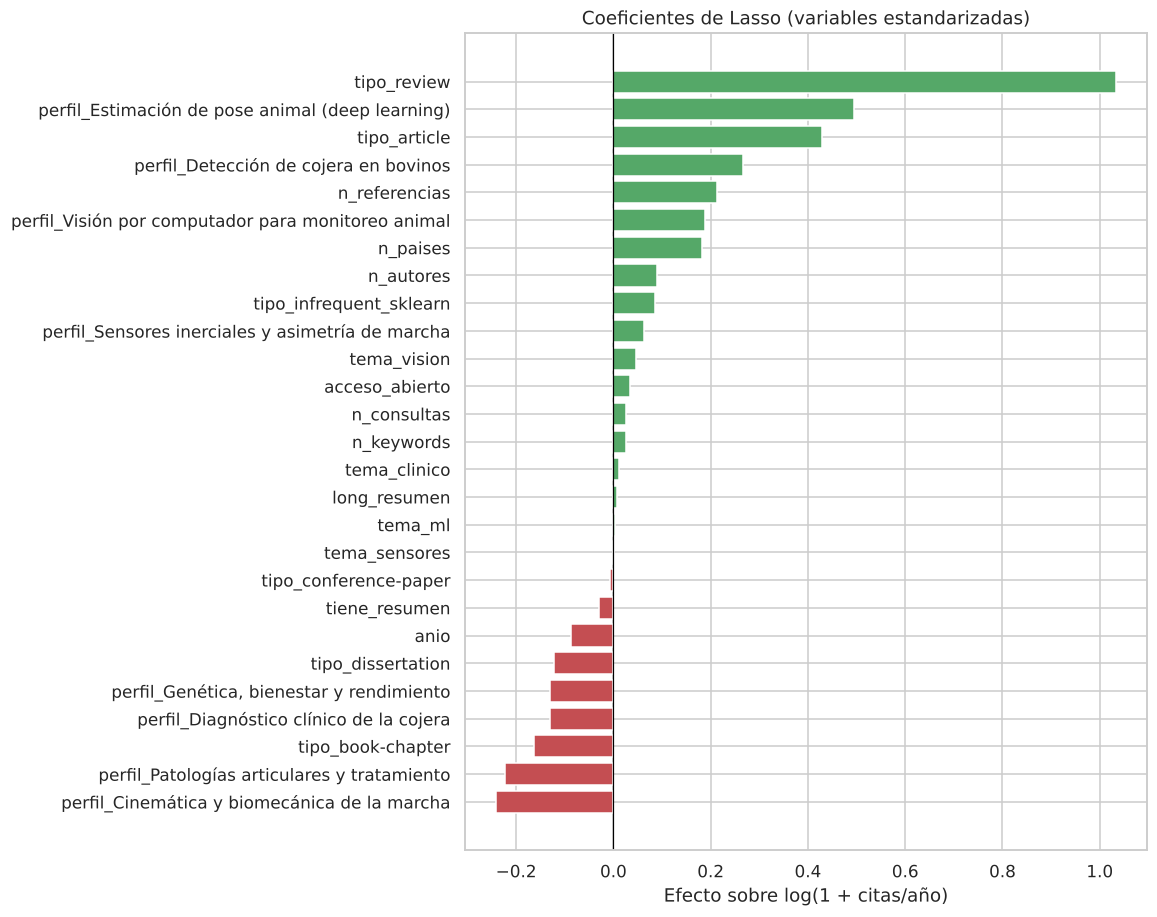

perfil_Cinemática y biomecánica de la marcha         -0.241
perfil_Patologías articulares y tratamiento          -0.222
tipo_book-chapter                                    -0.164
perfil_Diagnóstico clínico de la cojera              -0.130
perfil_Genética, bienestar y rendimiento             -0.129
tipo_dissertation                                    -0.123
anio                                                 -0.087
tiene_resumen                                        -0.029
tipo_conference-paper                                -0.006
tema_sensores                                         0.002
tema_ml                                               0.003
long_resumen                                          0.007
tema_clinico                                          0.012
n_keywords                                            0.025
n_consultas                                           0.026
acceso_abierto                                        0.035
tema_vision                             

In [4]:
lasso = mejores["Lasso"]
nombres = lasso.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lasso.named_steps["reg"].coef_, index=[n.split("__", 1)[1] for n in nombres])
coef = coef[coef.abs() > 1e-6].sort_values()
print(f"Variables retenidas por Lasso: {len(coef)} de {len(nombres)}")
plt.figure(figsize=(8, 0.32 * len(coef) + 1))
plt.barh(coef.index, coef.values, color=np.where(coef.values > 0, "#55A868", "#C44E52"))
plt.axvline(0, c="black", lw=.8)
plt.title("Coeficientes de Lasso (variables estandarizadas)"); plt.xlabel("Efecto sobre log(1 + citas/año)")
plt.savefig(FIG / "reg_lasso_coeficientes.png"); plt.show()
coef.round(3)

## Lectura
- El impacto de un artículo es **difícil de predecir** solo con sus metadatos. Los modelos lineales explican cerca del
  40 % de la variación en prueba; la regresión polinomial regularizada llega a ~50 % y el Random Forest a ~55 %, porque
  capturan interacciones, por ejemplo entre tema y tipo de documento.
- Ridge, Lasso y Elastic Net rinden igual que la regresión lineal: con 3.000 artículos y 29 variables no hay sobreajuste
  que corregir, y la regularización sirve sobre todo para **seleccionar variables** (Lasso).
- **Modelo elegido:** Lasso para interpretar, por su simplicidad, y Random Forest si el objetivo fuera solo predecir.
- Lasso confirma lo que mostraron el clustering y los outliers: los perfiles de **estimación de pose**, **detección en
  bovinos** y **visión por computador** se asocian con más citas por año, igual que la **colaboración** (más países y
  autores) y las revisiones. Los perfiles clínicos clásicos se asocian con menos impacto anual. El acceso abierto
  aporta un efecto positivo pequeño, y el año es negativo porque los trabajos recientes aún están acumulando citas.
- Para el proyecto, esto refuerza la decisión de trabajar con visión por computador y estimación de pose.

In [5]:
res.to_csv(OUT / "regresion_resultados.csv", index=False)
coef.to_csv(OUT / "regresion_lasso_coeficientes.csv", header=["coeficiente"])
print("Guardado.")

Guardado.
